# A/B test: should the online store roll out the new landing page?

**Client:** a South African online store. Marketing has built a new landing page and believes it converts better than the old one. Visitors were randomly shown either the old page (**control**) or the new page (**treatment**), and we recorded whether each one went on to buy (**converted**).

**Decision to support:** roll out the new page, keep the old one, or keep testing.

## Pre-registration: written before computing any conversion rate

These decisions are fixed **before** looking at the results, and committed to Git in that order, so they cannot be adjusted afterwards to make a result look significant. Changing the test, the threshold or the success criterion after seeing the data is called *p-hacking*, and it makes a p-value meaningless.

**Metric.** Conversion rate: the share of unique visitors who made a purchase.

**Hypotheses** (p_old and p_new are the true conversion rates of the two pages):

- **Null hypothesis H0:** p_new = p_old. The new page makes no difference.
- **Alternative hypothesis H1:** p_new ≠ p_old. The new page changes conversion, up or down.

The test is **two-sided** on purpose: a new page can also be worse, and we want to know if it is.

**Significance level:** α = 0.05. We accept a 5% risk of declaring a difference when there is none.

**Smallest lift worth acting on:** **+0.5 percentage points** (for example from 12.0% to 12.5%). A new page costs design and development time and carries rollout risk; a smaller lift would not pay for itself.

**Decision rule:**

| What the 95% confidence interval for (p_new - p_old) shows | Decision |
|---|---|
| Entirely above 0, and the plausible lift reaches +0.5 points | **Roll out** |
| Entirely below +0.5 points (a worthwhile lift is ruled out) | **Do not roll out** |
| Wide enough to include both 0 and +0.5 points | **Keep testing** |

**Test:** two-proportion z-test, with a 95% confidence interval for the difference.

---
# Step 2: Load the data

**Source:** `ab_data.csv` and `countries.csv`, the A/B test dataset from Udacity's Data Analyst Nanodegree, published at [github.com/jemc36/Udacity-DAND-AB-test-ecommerce](https://github.com/jemc36/Udacity-DAND-AB-test-ecommerce). It records a real-world style e-commerce experiment from January 2017. The files are downloaded once into `data/raw/`.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd

BASE = "https://raw.githubusercontent.com/jemc36/Udacity-DAND-AB-test-ecommerce/master/"
for name in ["ab_data.csv", "countries.csv"]:
    path = Path("../data/raw") / name
    if not path.exists():
        urllib.request.urlretrieve(BASE + name, path)

ab = pd.read_csv("../data/raw/ab_data.csv", parse_dates=["timestamp"])
countries = pd.read_csv("../data/raw/countries.csv")
print(ab.shape, countries.shape)
ab.head()

(294478, 5) (290584, 2)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [2]:
ab.info()

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[us]
 2   group         294478 non-null  str           
 3   landing_page  294478 non-null  str           
 4   converted     294478 non-null  int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 15.7 MB


In [3]:
for col in ["group", "landing_page", "converted"]:
    print(ab[col].value_counts().to_string(), "\n")
print("Countries:", countries.country.value_counts().to_dict())
print(f"Test ran from {ab.timestamp.min()} to {ab.timestamp.max()}")
print(f"Rows: {len(ab):,}   unique users: {ab.user_id.nunique():,}")

group
treatment    147276
control      147202 

landing_page
old_page    147239
new_page    147239 

converted
0    259241
1     35237 

Countries: {'US': 203619, 'UK': 72466, 'CA': 14499}
Test ran from 2017-01-02 13:42:05.378582 to 2017-01-24 13:41:54.460509
Rows: 294,478   unique users: 290,584


**Data dictionary**

| Column | Meaning |
|---|---|
| `user_id` | Visitor ID |
| `timestamp` | When the visitor saw the page |
| `group` | Experiment arm: `control` (should see the old page) or `treatment` (should see the new page) |
| `landing_page` | The page actually shown: `old_page` or `new_page` |
| `converted` | 1 if the visitor went on to buy, 0 if not |
| `country` | From `countries.csv`, joined on `user_id`: UK, US or CA |

Two things to check before testing: there are **more rows than unique users**, so some visitors appear twice, and `group` and `landing_page` are recorded separately, so they might not always agree.

---
# Step 3: Clean

## 1. Rows where the group and the page shown do not match

In [4]:
pd.crosstab(ab.group, ab.landing_page)

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [5]:
mismatch = ((ab.group == "control") & (ab.landing_page == "new_page")) | \
           ((ab.group == "treatment") & (ab.landing_page == "old_page"))
print(f"Mismatched rows: {mismatch.sum():,} ({mismatch.mean():.2%} of rows)")

Mismatched rows: 3,893 (1.32% of rows)


In 3,893 rows a control visitor saw the new page or a treatment visitor saw the old page. Something went wrong in how the page was served, and **we cannot know which record is right**: was the visitor assigned wrongly, or shown the wrong page?

**Decision: remove them.** The test compares people *assigned and shown* each page. Keeping misrouted visitors would mix the two experiences in both groups and blur the very difference we are measuring. At 1.3% of rows, removing them costs little power. In a real company I would also report the bug to the engineering team: a 1.3% routing error is worth fixing before the next test.

In [6]:
clean = ab[~mismatch].copy()
print(f"{len(clean):,} rows left")

290,585 rows left


## 2. Duplicate users

In [7]:
dupes = clean[clean.user_id.duplicated(keep=False)]
print(f"Users appearing more than once: {dupes.user_id.nunique()}")
dupes

Users appearing more than once: 1


,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


One visitor appears twice, both times in the treatment group with the new page and no conversion. Each visitor should count once (the unit of the test is the person, not the page view), so I keep the first visit.

In [8]:
clean = clean.drop_duplicates(subset="user_id", keep="first")
clean = clean.merge(countries, on="user_id", how="left")
print(f"{len(clean):,} unique visitors; missing country: {clean.country.isna().sum()}")
clean.to_csv("../data/processed/ab_clean.csv", index=False)

290,584 unique visitors; missing country: 0


## 3. Was the randomisation fair?

In [9]:
sizes = clean.group.value_counts()
print(sizes.to_string())
from scipy.stats import chisquare, chi2_contingency
print(f"\nSample ratio check (expected 50/50): p = {chisquare(sizes).pvalue:.3f}")
print(f"Country mix by group: chi-square p = {chi2_contingency(pd.crosstab(clean.group, clean.country)).pvalue:.3f}")
pd.crosstab(clean.group, clean.country, normalize="index").round(3)

group
treatment    145310
control      145274



Sample ratio check (expected 50/50): p = 0.947
Country mix by group: chi-square p = 0.409


country,CA,UK,US
group,,,
control,0.05,0.250,0.700
treatment,0.05,0.248,0.701


Both groups are almost exactly the same size, and the country mix is the same in each. A **sample ratio mismatch** (groups of noticeably different size) would be a warning that something broke the random assignment, and would make the test untrustworthy. Here nothing looks wrong, so differences in conversion can be credited to the page.

---
# Step 4: Conversion rates

In [10]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

summary = clean.groupby("group").agg(visitors=("converted", "size"), conversions=("converted", "sum"))
summary["conversion_rate"] = summary.conversions / summary.visitors
diff = summary.loc["treatment", "conversion_rate"] - summary.loc["control", "conversion_rate"]
print(f"Old page (control):   {summary.loc['control', 'conversion_rate']:.4%}")
print(f"New page (treatment): {summary.loc['treatment', 'conversion_rate']:.4%}")
print(f"Difference (new - old): {diff * 100:+.3f} percentage points")
summary

Old page (control):   12.0386%
New page (treatment): 11.8808%
Difference (new - old): -0.158 percentage points


,visitors,conversions,conversion_rate
group,,,
control,145274,17489,0.120386
treatment,145310,17264,0.118808


Test duration: 21 days, 2017-01-02 to 2017-01-24


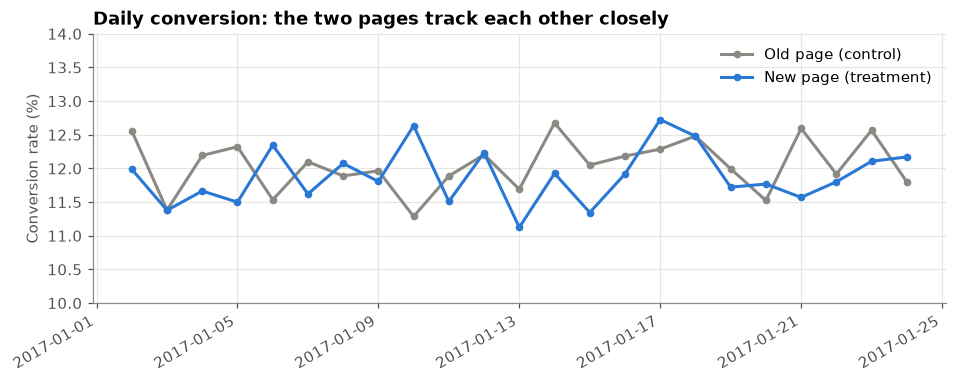

In [11]:
days = (clean.timestamp.max() - clean.timestamp.min()).days
print(f"Test duration: {days} days, {clean.timestamp.min().date()} to {clean.timestamp.max().date()}")
daily = clean.assign(date=clean.timestamp.dt.date).groupby(["date", "group"]).converted.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(daily.index, daily.control * 100, color=GREY, marker="o", markersize=4, label="Old page (control)")
ax.plot(daily.index, daily.treatment * 100, color=BLUE, marker="o", markersize=4, label="New page (treatment)")
ax.set_ylabel("Conversion rate (%)")
ax.set_ylim(10, 14)
ax.set_title("Daily conversion: the two pages track each other closely")
ax.legend()
fig.autofmt_xdate()
fig.savefig("../figures/daily_conversion.png")
plt.show()

The new page converts **slightly less** than the old one, by about 0.16 percentage points. The daily lines cross back and forth with no day where the new page clearly wins, and no early spike that fades (which would suggest a *novelty effect*, people clicking around a new design out of curiosity).

Whether a gap this small is real or just noise is what Step 5 tests.